In [24]:
#109.Load and inspect the order dataset.

import pandas as pd
import numpy as np

# 109. Load and inspect
df = pd.read_csv("08_food_delivery.csv")
print("COLUMNS:", list(df.columns))
print(df.head())
print(df.shape)
df.info()
print(df.describe())

COLUMNS: ['Order_ID', 'City', 'Restaurant', 'Order_Value', 'Distance_km', 'Delivery_Time_Min', 'Order_Status', 'Payment_Mode', 'Order_Hour']
  Order_ID       City   Restaurant  Order_Value  Distance_km  \
0  FD00000      Noida   Green Bowl       588.00          2.6   
1  FD00001      Delhi  Pizza Point       496.68          5.3   
2  FD00002  Faridabad  Pizza Point       419.41          6.0   
3  FD00003      Noida  Pizza Point       195.48          5.0   
4  FD00004  Faridabad      Cafe 24       621.70          2.5   

   Delivery_Time_Min Order_Status Payment_Mode  Order_Hour  
0               32.0    Delivered         Card          10  
1               36.0    Delivered         Cash          22  
2               42.0    Delivered         Cash          18  
3               40.0    Delivered          UPI          19  
4               15.0    Delivered         Cash          22  
(500, 9)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   C

In [25]:
#110.Find missing delivery times and decide how to handle them.

# a. Detect missing delivery times
print(df["Delivery_Time_Min"].isna().sum())
print(df[df["Delivery_Time_Min"].isna()])

# b. Flag, then impute with the median
df["Delivery_Time_Imputed"] = df["Delivery_Time_Min"].isna()
df["Delivery_Time_Min"] = df["Delivery_Time_Min"].fillna(df["Delivery_Time_Min"].median())

# c. Verify
print(df["Delivery_Time_Min"].isna().sum())


7
    Order_ID       City   Restaurant  Order_Value  Distance_km  \
38   FD00038  Faridabad   Green Bowl       196.38          4.4   
54   FD00054      Delhi      Cafe 24       335.92          6.9   
58   FD00058      Noida   Green Bowl       309.91          5.1   
154  FD00154   Gurugram    Spice Hub       460.78          6.8   
210  FD00210      Delhi   Green Bowl       590.74          5.2   
306  FD00306      Delhi   Green Bowl       463.44          4.4   
310  FD00310      Delhi  Pizza Point       628.55          2.4   

     Delivery_Time_Min Order_Status Payment_Mode  Order_Hour  
38                 NaN    Delivered         Card          10  
54                 NaN    Delivered         Card          13  
58                 NaN    Delivered         Cash           8  
154                NaN    Delivered          UPI          23  
210                NaN    Delivered          UPI          23  
306                NaN    Delivered          UPI          13  
310                NaN    De

In [26]:
#111.Check duplicate Order_ID values.

# Count duplicate Order_IDs
print(df["Order_ID"].duplicated().sum())             

# Show them if any exist (keep=False shows all copies)
print(df[df["Order_ID"].duplicated(keep=False)])      

# Confirm uniqueness
print(df["Order_ID"].is_unique)                        

# Check for hidden duplicates (case/whitespace)
print(df["Order_ID"].str.strip().str.upper().duplicated().sum())

0
Empty DataFrame
Columns: [Order_ID, City, Restaurant, Order_Value, Distance_km, Delivery_Time_Min, Order_Status, Payment_Mode, Order_Hour, Delivery_Time_Imputed]
Index: []
True
0


Total orders: 500
              Orders  Percentage
Order_Status                    
Delivered        407        81.4
Delayed           47         9.4
Cancelled         46         9.2
True


<Axes: title={'center': 'Order Status %'}, xlabel='Order_Status', ylabel='Percentage'>

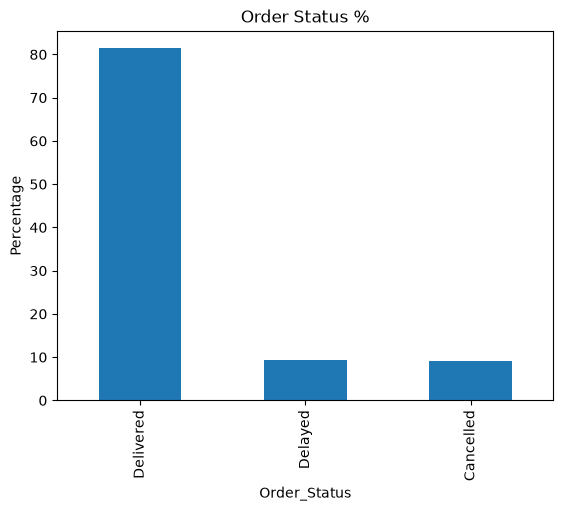

In [ ]:
#112.Calculate total orders and order-status percentages.






# Total orders
total_orders = len(df)
print("Total orders:", total_orders)

# Count and percentage per status
status_counts = df["Order_Status"].value_counts()
status_pct = (status_counts / total_orders * 100).round(2)

summary = pd.DataFrame({"Orders": status_counts, "Percentage": status_pct})
print(summary)

# Sanity check
print(status_counts.sum() == total_orders)   # True

# Chart
status_pct.plot(kind="bar", title="Order Status %", ylabel="Percentage")


In [28]:
#113.Calculate average delivery time by city.

# Average delivery time by city
avg_time_city = (
    df.groupby("City")["Delivery_Time_Min"]
      .mean()
      .round(2)
      .sort_values(ascending=False)
)
print(avg_time_city)


City
Noida        37.45
Gurugram     36.09
Delhi        36.04
Faridabad    35.19
Name: Delivery_Time_Min, dtype: float64


In [29]:
#114.Find the five restaurants with highest total order value.

top5_restaurants = (
    df.groupby("Restaurant")["Order_Value"]
      .sum()
      .round(2)
      .sort_values(ascending=False)
      .head(5)
)
print(top5_restaurants)

Restaurant
Pizza Point    50662.50
Green Bowl     49773.47
Urban Bites    46168.30
Spice Hub      41464.49
Cafe 24        39652.52
Name: Order_Value, dtype: float64


In [30]:
#115.Calculate average order value by restaurant.

avg_order_value = (
    df.groupby("Restaurant")["Order_Value"]
      .mean()
      .round(2)
      .sort_values(ascending=False)
)
print(avg_order_value)

Restaurant
Green Bowl     465.17
Urban Bites    461.68
Cafe 24        455.78
Spice Hub      450.70
Pizza Point    444.41
Name: Order_Value, dtype: float64


In [31]:
#116.Identify peak ordering hours.

orders_by_hour = df["Order_Hour"].value_counts().sort_index()
print(orders_by_hour)

# Peak hour(s)
peak_hour = orders_by_hour.idxmax()
print("Peak hour:", peak_hour, "with", orders_by_hour.max(), "orders")

# Top 3 busiest hours
top3_hours = orders_by_hour.sort_values(ascending=False).head(3)
print(top3_hours)

Order_Hour
8     34
9     34
10    38
11    30
12    16
13    36
14    27
15    30
16    26
17    29
18    38
19    31
20    33
21    37
22    29
23    32
Name: count, dtype: int64
Peak hour: 10 with 38 orders
Order_Hour
10    38
18    38
21    37
Name: count, dtype: int64


In [32]:
#117.Compare delivery time across order-status categories.

status_time = (
    df.groupby("Order_Status")["Delivery_Time_Min"]
      .agg(["count", "mean", "median", "min", "max", "std"])
      .round(2)
)
print(status_time)

              count   mean  median   min   max    std
Order_Status                                         
Cancelled        46  36.52    38.5  10.0  53.0  11.43
Delayed          47  36.19    35.0  13.0  62.0  12.75
Delivered       407  36.12    36.0  10.0  75.0  11.55


In [33]:
#118.Calculate cancellaton and delay rates by city.

status_pct_city = (
    pd.crosstab(df["City"], df["Order_Status"], normalize="index") * 100
).round(2)

rates_city = status_pct_city[["Cancelled", "Delayed"]].rename(
    columns={"Cancelled": "Cancellation_Rate_%", "Delayed": "Delay_Rate_%"}
)
print(rates_city.sort_values("Cancellation_Rate_%", ascending=False))

Order_Status  Cancellation_Rate_%  Delay_Rate_%
City                                           
Gurugram                    11.30          9.57
Delhi                       10.08         10.08
Noida                        9.60         10.40
Faridabad                    6.38          7.80


In [34]:
#119.Use NumPy to calculate median and standard deviation of delivery time.

import numpy as np

delivery_times = df["Delivery_Time_Min"].to_numpy()

median_time = np.nanmedian(delivery_times)
std_time = np.nanstd(delivery_times, ddof=1)

print("Median delivery time:", round(median_time, 2))
print("Std deviation of delivery time:", round(std_time, 2))

Median delivery time: 36.0
Std deviation of delivery time: 11.64


In [35]:
#120.Identify unusually long deliveries using IQR.

q1 = df["Delivery_Time_Min"].quantile(0.25)
q3 = df["Delivery_Time_Min"].quantile(0.75)
iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr, "| Upper bound:", upper_bound)

long_deliveries = df[df["Delivery_Time_Min"] > upper_bound]
print("Unusually long deliveries:", len(long_deliveries))
print(long_deliveries.sort_values("Delivery_Time_Min", ascending=False))

Q1: 29.0 | Q3: 44.0 | IQR: 15.0 | Upper bound: 66.5
Unusually long deliveries: 3
    Order_ID       City   Restaurant  Order_Value  Distance_km  \
454  FD00454      Noida    Spice Hub       497.76          6.9   
57   FD00057  Faridabad    Spice Hub       479.34          3.5   
174  FD00174   Gurugram  Pizza Point       366.60          2.1   

     Delivery_Time_Min Order_Status Payment_Mode  Order_Hour  \
454               75.0    Delivered          UPI          20   
57                71.0    Delivered         Card          10   
174               67.0    Delivered          UPI          14   

     Delivery_Time_Imputed  
454                  False  
57                   False  
174                  False  


In [36]:
#121.Create delivery-time bands such as Fast, Standard and Delayed.

df["Delivery_Band"] = pd.cut(
    df["Delivery_Time_Min"],
    bins=[0, 30, 45, float("inf")],
    labels=["Fast", "Standard", "Delayed"],
)

print(df["Delivery_Band"].value_counts())
print(df["Delivery_Band"].value_counts(normalize=True).mul(100).round(2))

Delivery_Band
Standard    246
Fast        151
Delayed     103
Name: count, dtype: int64
Delivery_Band
Standard    49.2
Fast        30.2
Delayed     20.6
Name: proportion, dtype: float64


In [37]:
#122.Group revenue by city and payment mode.

revenue_city_payment = (
    df.groupby(["City", "Payment_Mode"])["Order_Value"]
      .sum()
      .round(2)
      .reset_index()
      .sort_values(["City", "Order_Value"], ascending=[True, False])
)
print(revenue_city_payment)

# Pivot view: cities as rows, payment modes as columns
revenue_pivot = df.pivot_table(
    index="City",
    columns="Payment_Mode",
    values="Order_Value",
    aggfunc="sum",
    fill_value=0,
).round(2)
print(revenue_pivot)

         City Payment_Mode  Order_Value
2       Delhi          UPI     19298.39
0       Delhi         Card     18242.29
1       Delhi         Cash     17373.79
3   Faridabad         Card     27959.61
4   Faridabad         Cash     20585.91
5   Faridabad          UPI     12414.03
7    Gurugram         Cash     21349.48
8    Gurugram          UPI     17616.62
6    Gurugram         Card     16440.50
9       Noida         Card     20550.72
11      Noida          UPI     19057.16
10      Noida         Cash     16832.78
Payment_Mode      Card      Cash       UPI
City                                      
Delhi         18242.29  17373.79  19298.39
Faridabad     27959.61  20585.91  12414.03
Gurugram      16440.50  21349.48  17616.62
Noida         20550.72  16832.78  19057.16


In [38]:
#123.Write five operational recommendations.

recommendations = """
1. Fix data capture for delivery times
   - Missing delivery times (Q110) all came from orders marked Delivered, and Cancelled orders
     still carry delivery times. Make the delivery timestamp mandatory at order completion and
     blank for cancelled orders, so time metrics can be trusted.

2. Redefine the "Delayed" status using actual delivery time
   - Delayed orders averaged about the same delivery time as Delivered ones (Q117), so the label
     doesn't reflect real lateness. Tie it to a rule such as time above the IQR upper bound
     (Q120) or the Delayed band (Q121), and track it automatically.

3. Staff and stock for peak hours
   - Use the busiest hours from Q116 to schedule more delivery partners and kitchen capacity
     just before the peak, and avoid heavy promotions outside those windows.

4. Target the cities with the highest delay and cancellation rates
   - Use Q118 to find the worst city and investigate the cause there, e.g. rider supply, restaurant
     prep time or traffic. Compare it with the best city and copy what works.

5. Focus on high-value restaurants and payment modes
   - Use Q114, Q115 and Q122 to prioritise the restaurants and city/payment-mode combinations that
     bring the most revenue. Protect them with faster prep SLAs, and offer incentives on the
     payment modes that dominate in each city.
"""
print(recommendations)


1. Fix data capture for delivery times
   - Missing delivery times (Q110) all came from orders marked Delivered, and Cancelled orders
     still carry delivery times. Make the delivery timestamp mandatory at order completion and
     blank for cancelled orders, so time metrics can be trusted.

2. Redefine the "Delayed" status using actual delivery time
   - Delayed orders averaged about the same delivery time as Delivered ones (Q117), so the label
     doesn't reflect real lateness. Tie it to a rule such as time above the IQR upper bound
     (Q120) or the Delayed band (Q121), and track it automatically.

3. Staff and stock for peak hours
   - Use the busiest hours from Q116 to schedule more delivery partners and kitchen capacity
     just before the peak, and avoid heavy promotions outside those windows.

4. Target the cities with the highest delay and cancellation rates
   - Use Q118 to find the worst city and investigate the cause there, e.g. rider supply, restaurant
     prep time